In [6]:
from typing import TypedDict

class PortfolioState(TypedDict):
    amount_usd : float
    total_usd : float
    total_inr : float

In [10]:
def calc_total(state: PortfolioState) -> PortfolioState:
    state["total_usd"] = state["amount_usd"] * 1.08
    return state
def convert_to_inr(state: PortfolioState) -> PortfolioState:
    state["total_inr"] = state["total_usd"] * 90
    return state

In [11]:
from langgraph.graph import StateGraph, START, END

builder = StateGraph(PortfolioState)
builder.add_node("calc_total_node",calc_total)
builder.add_node("convert_to_inr_node",convert_to_inr)
builder.add_edge(START, "calc_total_node")
builder.add_edge("calc_total_node","convert_to_inr_node")
builder.add_edge("convert_to_inr_node",END)

graph = builder.compile()

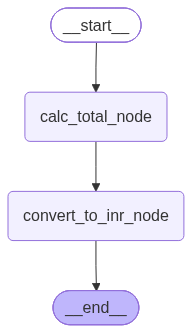

In [12]:
from IPython.display import Image, display
display(Image(graph.get_graph().draw_mermaid_png()))

In [13]:
graph.invoke({"amount_usd":10000})

{'amount_usd': 10000, 'total_usd': 10800.0, 'total_inr': 972000.0}